[10.]


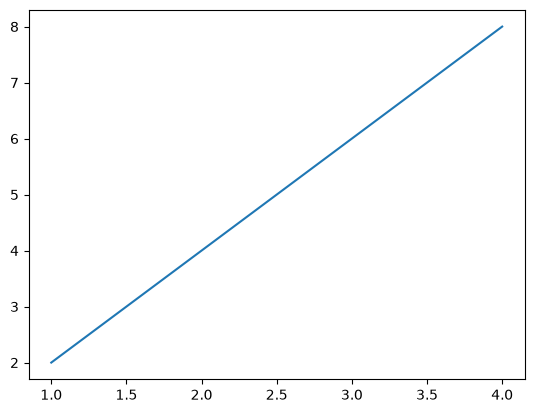

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

x = np.array([[1], [2], [3], [4]])
y = np.array([2, 4, 6, 8])
print(LinearRegression().fit(x, y).predict([[5]]))

plt.plot(x, y)
plt.show()

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)

final_score = (
    (0.5 * study_hours)
    + (0.3 * attendance)
    + (0.2 * previous_mark)
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    'study_hours': study_hours,
    'attendance': attendance,
    'previous_mark': previous_mark,
    'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan
df.loc[99, 'study_hours'] = 50
df.loc[98, 'attendance'] = -10

print(df)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


In [2]:
# Inspect the dataset
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDescriptive statistics before cleaning:")
print(df.describe())

# Identify the outlier
print("\nOutlier record:")
print(df[df['study_hours'] == 50])

# Replace impossible attendance value with NaN
df.loc[df['attendance'] < 0, 'attendance'] = np.nan

# Replace the outlier with NaN because 50 hours is an
# implausible value for this dataset and may be corrupted
df.loc[df['study_hours'] == 50, 'study_hours'] = np.nan

# Fill missing values with the median of each column
df = df.fillna(df.median())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

Dataset shape: (100, 4)

Missing values:
study_hours      6
attendance       0
previous_mark    0
final_score      0
dtype: int64

Descriptive statistics before cleaning:
       study_hours  attendance  previous_mark  final_score
count    94.000000  100.000000     100.000000   100.000000
mean      5.218916   84.267225      70.973444    42.691957
std       5.014751   13.476443      16.264243     6.086797
min      -0.239490  -10.000000      21.380990    29.163251
25%       3.731467   76.829717      60.168347    38.188854
50%       4.812342   85.841072      71.465436    42.763014
75%       5.744365   90.381704      80.566562    46.688328
max      50.000000  112.201692     127.790972    57.171201

Outlier record:
    study_hours  attendance  previous_mark  final_score
99         50.0   73.570297      79.444433     46.41447

Missing values after cleaning:
study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64

Cleaned dataset shape: (100, 4)


In [3]:
print("Mean:")
print(df.mean())

print("\nMedian:")
print(df.median())

print("\nStandard deviation:")
print(df.std())

print("\nComplete summary:")
print(df.describe())

Mean:
study_hours       4.739590
attendance       85.227190
previous_mark    70.973444
final_score      42.691957
dtype: float64

Median:
study_hours       4.768703
attendance       85.996514
previous_mark    71.465436
final_score      42.763014
dtype: float64

Standard deviation:
study_hours       1.774787
attendance        9.536937
previous_mark    16.264243
final_score       6.086797
dtype: float64

Complete summary:
       study_hours  attendance  previous_mark  final_score
count   100.000000  100.000000     100.000000   100.000000
mean      4.739590   85.227190      70.973444    42.691957
std       1.774787    9.536937      16.264243     6.086797
min      -0.239490   65.812288      21.380990    29.163251
25%       3.798189   76.943395      60.168347    38.188854
50%       4.768703   85.996514      71.465436    42.763014
75%       5.716367   90.381704      80.566562    46.688328
max       8.704556  112.201692     127.790972    57.171201


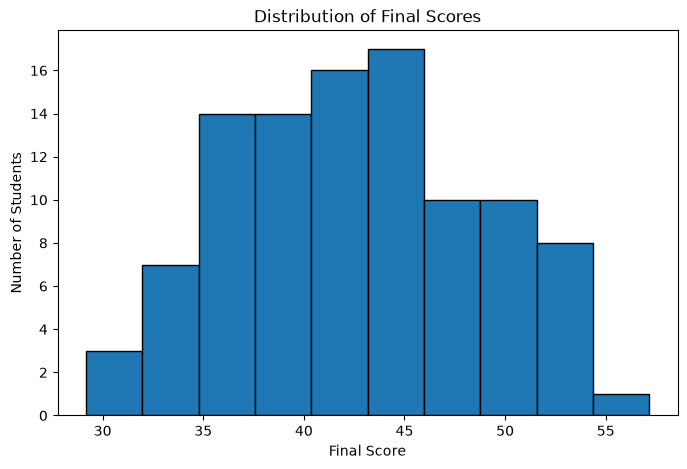

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['final_score'], bins=10, edgecolor='black')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')
plt.title('Distribution of Final Scores')
plt.show()


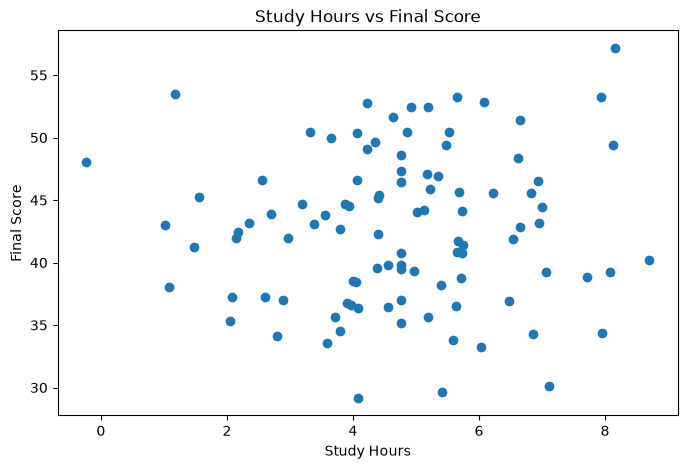

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df['study_hours'], df['final_score'])
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.title('Study Hours vs Final Score')
plt.show()

In [6]:
correlation = df['study_hours'].corr(df['final_score'], method='pearson')

print("Pearson correlation:", correlation)


Pearson correlation: 0.049887094970462724


In [7]:
# Select the first student's features, excluding final_score
x = df.loc[0, ['study_hours', 'attendance', 'previous_mark']].to_numpy()

# Define the weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate the dot product and predicted value
y = np.dot(w, x) + b

print("Student feature vector:", x)
print("Weight vector:", w)
print("Bias:", b)
print("Predicted score:", y)

Student feature vector: [ 4.76870344 70.84629258 75.36681041]
Weight vector: [0.5 0.2 0.4]
Bias: 5
Predicted score: 51.70033439560063


In [8]:
# Standardize study_hours
df['study_hours_standardized'] = (
    df['study_hours'] - df['study_hours'].mean()
) / df['study_hours'].std()

# Standardize previous_mark
df['previous_mark_standardized'] = (
    df['previous_mark'] - df['previous_mark'].mean()
) / df['previous_mark'].std()

print(df[[
    'study_hours',
    'study_hours_standardized',
    'previous_mark',
    'previous_mark_standardized'
]].head())

print("\nStandardized means:")
print(df[[
    'study_hours_standardized',
    'previous_mark_standardized'
]].mean())

print("\nStandardized standard deviations:")
print(df[[
    'study_hours_standardized',
    'previous_mark_standardized'
]].std())

   study_hours  study_hours_standardized  previous_mark  \
0     4.768703                  0.016404      75.366810   
1     4.768703                  0.016404      78.411768   
2     4.768703                  0.016404      86.245769   
3     4.768703                  0.016404      85.807031   
4     4.768703                  0.016404      49.334959   

   previous_mark_standardized  
0                    0.270124  
1                    0.457342  
2                    0.939012  
3                    0.912037  
4                   -1.330433  

Standardized means:
study_hours_standardized      1.859277e-16
previous_mark_standardized    7.238654e-16
dtype: float64

Standardized standard deviations:
study_hours_standardized      1.0
previous_mark_standardized    1.0
dtype: float64
